# COSYNE abstract figures

This notebook stages the layouts specified in `figures_plan.md`. Figure 1 uses real three-animal movement results and the supplied panel A SVG. Figure 2 uses real cell-level corrected model scores; no synthetic Figure 2 preview is included.

The final section explains how to switch the same layouts to cached real tables from `movement_groups_encoding.ipynb`.

In [125]:
from pathlib import Path
import importlib
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

NOTEBOOKS_DIR = Path.cwd().resolve()
if not (NOTEBOOKS_DIR / "cosyne_abstract_figures.py").exists():
    candidate = NOTEBOOKS_DIR / "notebooks"
    if (candidate / "cosyne_abstract_figures.py").exists():
        NOTEBOOKS_DIR = candidate
if str(NOTEBOOKS_DIR) not in sys.path:
    sys.path.insert(0, str(NOTEBOOKS_DIR))

import cosyne_abstract_figures as caf
caf = importlib.reload(caf)

%config InlineBackend.figure_format = 'retina'
print(f"Figure code: {NOTEBOOKS_DIR / 'cosyne_abstract_figures.py'}")

Figure code: /media/labuser/NA_1_2025/spyglass_common/notebooks/cosyne_abstract_figures.py


## Figure 1 — movement is structured by task progress

Panel A reloads `/home/labuser/Downloads/progress.svg` each time the figure cell runs. Panel B shows three-animal movement profiles; panel C shows mean cross-validated predictability. To apply a change in the profile calculation, set `RECOMPUTE_FIGURE_1_PROFILES = True` in the next cell for one run. Panel D remains pending.

Real Figure 1: three animal curves in 1B; animal-mean R² in 1C
Saved SVG: /media/labuser/NA_1_2025/spyglass_common/notebooks/abstract_figures/figure_1_movement_structure.svg


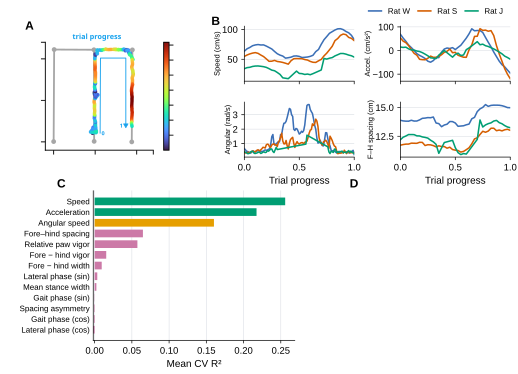

In [126]:
import subprocess

caf = importlib.reload(caf)
PROGRESS_SVG_PATH = Path("/home/labuser/Downloads/progress.svg")
RECOMPUTE_FIGURE_1_PROFILES = False  # Set True for one run after changing profile settings.
if RECOMPUTE_FIGURE_1_PROFILES:
    for animal in ("Wilbur", "Senor", "J"):
        subprocess.run(
            [sys.executable, str(NOTEBOOKS_DIR / "figure1_multi_animal_predictability.py"), animal, "--profiles"],
            check=True,
        )

real_figure_1_profiles = caf.load_multi_animal_progress_profiles()
real_figure_1_scores = caf.load_multi_animal_progress_r2()
real_figure_1_mean_r2 = caf.mean_animal_progress_r2(real_figure_1_scores)

real_figure_1, real_figure_1_panels = caf.assemble_figure_1(
    real_figure_1_profiles,
    real_figure_1_mean_r2,
    progress_r2_xlabel="Mean CV R²",
    schematic_svg_path=PROGRESS_SVG_PATH,
    schematic_svg_viewbox=(85, -20, 530, 490),  # Include the title, track, and colorbar.
)
print("Real Figure 1: three animal curves in 1B; animal-mean R² in 1C")
SAVE_FIGURE_1_SVG = True
if SAVE_FIGURE_1_SVG:
    from IPython.display import SVG, display
    (svg_path,) = caf.save_composite(
        real_figure_1,
        NOTEBOOKS_DIR / "abstract_figures/figure_1_movement_structure",
        formats=("svg",),
    )
    print(f"Saved SVG: {svg_path}")
    plt.close(real_figure_1)
    display(SVG(filename=str(svg_path)))
else:
    plt.show()

## Figure 2 — real cell-population results

Panel A is blank for manual artwork. B keeps the four-model violin and cell-point plot; C keeps Task/Movement total-versus-unique violins and cell points; D keeps the six-subgroup violins and cell points. Only panel layout and spacing changed. Every quantitative panel uses the same cells with complete scores across all 16 models.

The next cell loads cached corrected scores, or calculates them once from saved out-of-fold prediction shards if the cache is absent. This does not refit models and may take several minutes.

Loaded real cell-level scores: /media/labuser/NA_1_2025/spyglass_common/notebooks/abstract_figure_data/corrected_model_d2_by_unit.pkl
Figure 2: 252 matched cells
Saved real Figure 2 SVG: /media/labuser/NA_1_2025/spyglass_common/notebooks/abstract_figures/figure_2_neural_encoding.svg


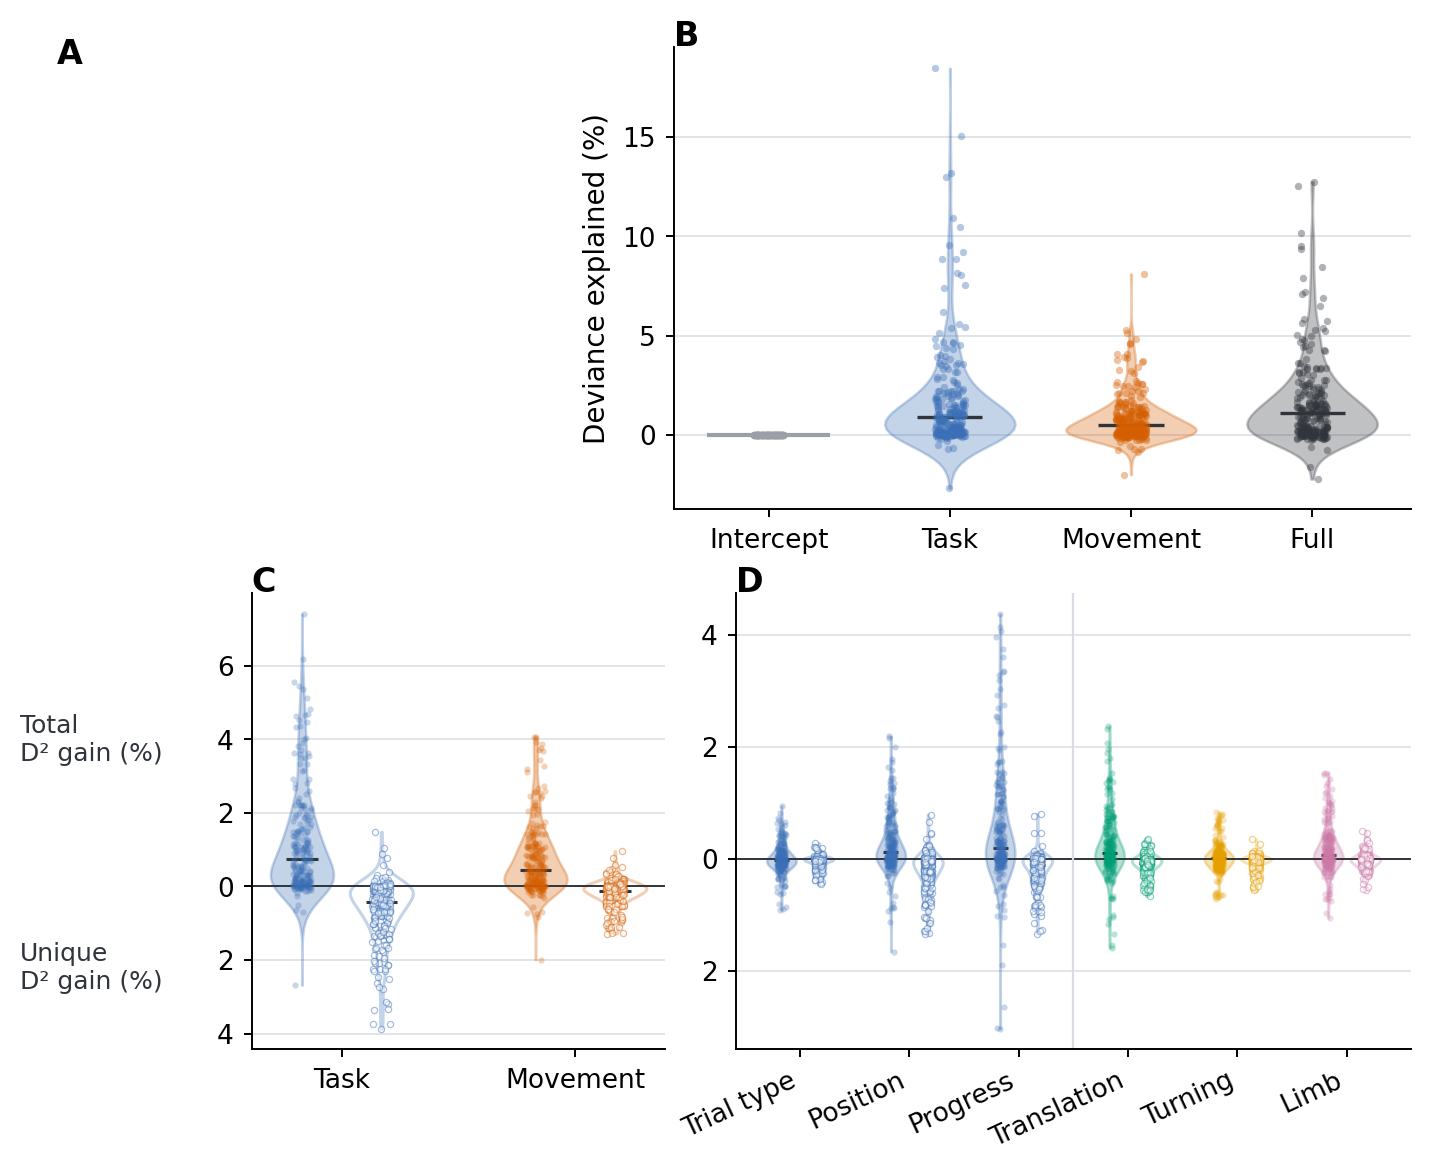

: 

In [ ]:
caf = importlib.reload(caf)
ABSTRACT_CACHE_DIR = NOTEBOOKS_DIR / "abstract_figure_data"
score_path = ABSTRACT_CACHE_DIR / "corrected_model_d2_by_unit.pkl"
if score_path.is_file():
    corrected_model_d2_by_unit = pd.read_pickle(score_path)
    print(f"Loaded real cell-level scores: {score_path}")
else:
    from movement_model_results import calculate_saved_oof_deviance_explained

    model_results_dir = caf.DEFAULT_FIGURE1_BUNDLE.parent / "model_fits"
    if not model_results_dir.is_dir():
        raise FileNotFoundError(f"Saved model fits not found: {model_results_dir}")
    print("Calculating corrected outer-CV D² from saved predictions (no model refit)...")
    corrected_model_d2_by_unit, _ = calculate_saved_oof_deviance_explained(
        model_results_dir,
        model_names=caf.FIGURE2_REQUIRED_MODELS,
        n_jobs=4,
    )
    ABSTRACT_CACHE_DIR.mkdir(parents=True, exist_ok=True)
    corrected_model_d2_by_unit.to_pickle(score_path)
    print(f"Cached real cell-level scores: {score_path}")

real_population_scores, real_subgroup_gains, real_task_movement_gains = (
    caf.prepare_figure_2_tables(corrected_model_d2_by_unit)
)
print(f"Figure 2: {len(real_subgroup_gains)} matched cells")
real_figure_2, real_figure_2_panels = caf.assemble_figure_2_grid(
    real_population_scores,
    real_subgroup_gains,
    real_task_movement_gains,
)
(figure_2_svg_path,) = caf.save_composite(
    real_figure_2,
    NOTEBOOKS_DIR / "abstract_figures/figure_2_neural_encoding",
    formats=("svg",),
)
print(f"Saved real Figure 2 SVG: {figure_2_svg_path}")
plt.show()

## Export real figures

After inspecting the real-data layout, set the flag below to write PDF and SVG copies.

In [128]:
EXPORT_REAL_FIGURES = False

if EXPORT_REAL_FIGURES:
    output_dir = NOTEBOOKS_DIR / "abstract_figures"
    output_paths = [
        *caf.save_composite(
            real_figure_1, output_dir / "figure_1_movement_structure"
        ),
    ]
    output_paths.extend(caf.save_composite(
        real_figure_2, output_dir / "figure_2_neural_encoding"
    ))
    print(*output_paths, sep="\n")